# Multiclass intrusion detection
## Reproduce the frozen results

This notebook trains the configurations in **Intrusion Model Improvement and Results.zip** and recomputes the grouped validation, full held-out comparison, per-classifier comparison, log-byte regression, and clustering. The original capture archive is the data input.

Place the original `archive.zip` in the repository’s `dataset/` directory and leave it compressed. The setup cell locates the archive when Jupyter starts in the repository root or the `benchmarking/` directory. Use Python 3.12 and install the packages in `requirements.txt`. Edit `ARCHIVE` below if the archive is stored elsewhere. On a full run, the notebook stages about 520 MB of temporary holdout data and scores 3.44 million flows. Allow several minutes.

In [1]:
from pathlib import Path

# Paths are relative to the Jupyter kernel's working directory.
candidates = (Path("dataset/archive.zip"), Path("../dataset/archive.zip"), Path("archive.zip"))
ARCHIVE = next((path for path in candidates if path.is_file()), candidates[0])

In [2]:
import json
from tempfile import TemporaryDirectory
from zipfile import ZipFile

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display
from scipy.linalg import solve
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    adjusted_rand_score, confusion_matrix, mean_absolute_error, pairwise_distances, r2_score,
    silhouette_score,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits

if sklearn.__version__ != "1.7.2":
    raise RuntimeError(f"Use scikit-learn 1.7.2 for the frozen configs. Found {sklearn.__version__}.")

print(f"scikit-learn {sklearn.__version__}, NumPy {np.__version__}, "
      f"pandas {pd.__version__}, SciPy {scipy.__version__}, Matplotlib {matplotlib.__version__}")

scikit-learn 1.7.2, NumPy 2.5.5, pandas 2.3.3, SciPy 1.18.1, Matplotlib 3.11.2


## Prepare the fixed data split

The study assigns ten-minute blocks within each capture to the holdout or one of three validation buckets. The archive is streamed once to rebuild the original 109,458-row development sample, the expanded 344,208-row fitting pool, and all 3,439,552 held-out flows. Both fitting pools draw from the same development blocks.

In [3]:
CHUNK = 125_000


BLOCK_MINUTES = 10


SEED = 1729


FEATURES = [
    "Protocol", "Flow Duration", "Tot Fwd Pkts", "Tot Bwd Pkts",
    "TotLen Fwd Pkts", "TotLen Bwd Pkts", "Fwd Pkt Len Max", "Fwd Pkt Len Min",
    "Fwd Pkt Len Std", "Bwd Pkt Len Max", "Bwd Pkt Len Min", "Bwd Pkt Len Std",
    "Flow Byts/s", "Flow Pkts/s", "Flow IAT Mean", "Flow IAT Std", "Flow IAT Max",
    "Fwd IAT Mean", "Fwd IAT Std", "Bwd IAT Mean", "Bwd IAT Std", "Fwd PSH Flags",
    "Fwd Header Len", "Bwd Header Len", "FIN Flag Cnt", "SYN Flag Cnt", "RST Flag Cnt",
    "PSH Flag Cnt", "ACK Flag Cnt", "URG Flag Cnt", "Down/Up Ratio", "Pkt Len Mean",
    "Pkt Len Std", "Init Fwd Win Byts", "Init Bwd Win Byts", "Active Mean",
    "Active Std", "Idle Mean", "Idle Std",
]


LABELS = ["Benign", "Bot", "Brute Force", "DoS", "DDoS", "Infiltration", "Web Attack"]


IDENTITY_COLUMNS = ["Timestamp", "Label"]

CLASSES = np.arange(len(LABELS))

DATA = {'capture_members': {'02-14-2018.csv': [358223333, 1195817239],
                     '02-15-2018.csv': [375945899, 3870072833],
                     '02-16-2018.csv': [333723605, 395830762],
                     '02-20-2018.csv': [4054925350, 3119562513],
                     '02-21-2018.csv': [328893673, 1370206535],
                     '02-22-2018.csv': [382636202, 3854324905],
                     '02-23-2018.csv': [382840456, 2499666463],
                     '02-28-2018.csv': [209249758, 994541139],
                     '03-01-2018.csv': [107842858, 251771788],
                     '03-02-2018.csv': [352368373, 3489003198]},
 'time_blocks_by_bucket': {'02-14-2018': [[7, 9, 10, 25, 54, 65, 67, 70, 71, 73],
                                          [11, 13, 16, 23, 27, 30, 33, 50, 55, 58, 62, 64, 69, 72, 74],
                                          [8, 14, 19, 20, 21, 22, 26, 28, 51, 52, 53, 56, 59, 63, 75, 76],
                                          [6, 12, 15, 17, 18, 24, 29, 31, 32, 57, 60, 61, 66, 68, 77]],
                           '02-15-2018': [[11, 13, 17, 24, 32, 33, 51, 54, 62, 70, 75, 76],
                                          [14, 22, 28, 31, 34, 35, 50, 57, 58, 59, 60, 65, 66, 67, 68, 71],
                                          [6, 15, 19, 20, 21, 23, 25, 27, 52, 55, 61, 69],
                                          [7, 8, 9, 10, 12, 16, 18, 26, 29, 30, 53, 56, 63, 64, 72, 73, 74, 77]],
                           '02-16-2018': [[6, 9, 60, 61, 63, 64, 66, 68, 73, 74, 77],
                                          [52, 55, 57, 58, 69, 70, 72],
                                          [7, 51, 56, 59, 62, 65, 67, 71],
                                          [8, 10, 50, 53, 54, 75, 76]],
                           '02-20-2018': [[7, 9, 10, 18, 19, 23, 25, 33, 36, 37, 38, 51, 55, 56, 58, 67, 75],
                                          [6, 8, 16, 28, 30, 32, 48, 49, 52, 61, 62, 66, 68, 69, 73, 77],
                                          [11,
                                           17,
                                           20,
                                           24,
                                           27,
                                           29,
                                           34,
                                           35,
                                           39,
                                           43,
                                           45,
                                           46,
                                           47,
                                           50,
                                           54,
                                           57,
                                           60,
                                           63,
                                           64,
                                           71,
                                           76],
                                          [12,
                                           13,
                                           14,
                                           15,
                                           21,
                                           22,
                                           26,
                                           31,
                                           40,
                                           41,
                                           42,
                                           44,
                                           53,
                                           59,
                                           65,
                                           70,
                                           72,
                                           74]],
                           '02-21-2018': [[15, 58],
                                          [11, 12, 52, 57, 64],
                                          [14, 55, 56, 59, 61, 62],
                                          [13, 51, 53, 54, 60, 63]],
                           '02-22-2018': [[11, 15, 22, 24, 26, 52, 60, 62, 70, 75, 76, 77],
                                          [7, 8, 16, 17, 19, 29, 30, 51, 59, 67, 69, 71, 72, 73],
                                          [6, 9, 18, 20, 27, 28, 50, 54, 56, 57, 61, 63, 64, 68, 74],
                                          [10, 12, 13, 14, 21, 23, 25, 31, 32, 33, 53, 55, 58, 65, 66]],
                           '02-23-2018': [[16, 17, 23, 24, 26, 28, 31, 52, 57, 59, 62, 69, 70, 71, 75],
                                          [7, 8, 9, 11, 18, 22, 25, 30, 49, 53, 54, 56, 60, 61, 63, 68, 73, 77],
                                          [6, 10, 12, 13, 14, 19, 20, 21, 27, 32, 64, 72],
                                          [15, 29, 33, 50, 51, 55, 58, 65, 66, 67, 74, 76]],
                           '02-28-2018': [[7, 9, 10, 11, 13, 23, 24, 31, 34, 55, 59, 61, 71, 72, 76],
                                          [12, 15, 16, 17, 18, 21, 22, 25, 33, 35, 53, 54, 60, 62, 68, 70, 75],
                                          [14, 27, 28, 29, 32, 52, 56, 57, 58, 65, 66, 69],
                                          [6, 8, 19, 20, 26, 30, 50, 51, 63, 64, 67, 73, 74, 77]],
                           '03-01-2018': [[7, 8, 21, 24, 61, 67, 70, 76],
                                          [10,
                                           11,
                                           14,
                                           18,
                                           22,
                                           23,
                                           25,
                                           27,
                                           29,
                                           31,
                                           32,
                                           51,
                                           52,
                                           54,
                                           55,
                                           56,
                                           58,
                                           59,
                                           64,
                                           68,
                                           71],
                                          [9, 12, 20, 26, 30, 33, 34, 50, 66, 69, 74, 75, 77],
                                          [6, 13, 15, 16, 17, 19, 28, 49, 53, 57, 60, 62, 63, 65, 72, 73]],
                           '03-02-2018': [[7, 12, 21, 28, 52, 54, 64, 69, 70, 75, 77],
                                          [6, 9, 17, 31, 32, 59, 63, 65, 68, 76],
                                          [8, 14, 16, 22, 23, 25, 29, 30, 33, 53, 57, 60, 62, 72, 73, 74],
                                          [10, 11, 13, 15, 18, 19, 20, 24, 26, 27, 55, 56, 58, 61, 66, 67, 71]]},
 'label_codes': {'Benign': 0,
                 'FTP-BruteForce': 2,
                 'SSH-Bruteforce': 2,
                 'DoS attacks-GoldenEye': 3,
                 'DoS attacks-Slowloris': 3,
                 'DoS attacks-Hulk': 3,
                 'DoS attacks-SlowHTTPTest': 3,
                 'DDoS attacks-LOIC-HTTP': 4,
                 'DDOS attack-HOIC': 4,
                 'DDOS attack-LOIC-UDP': 4,
                 'Brute Force -Web': 6,
                 'Brute Force -XSS': 6,
                 'SQL Injection': 6,
                 'Infilteration': 5,
                 'Bot': 1},
 'population': [[3032878, 75556, 80733, 84562, 134542, 31151, 130],
                [3283069, 57258, 101159, 42255, 239821, 39983, 305],
                [3400570, 73943, 80307, 58506, 422835, 32223, 255],
                [3768177, 79434, 118750, 468977, 466735, 58577, 238]],
 'original_counts': [[3032878, 75556, 80733, 84562, 134542, 31151, 130],
                     [26189, 1183, 1146, 1215, 1784, 1187, 305],
                     [27195, 1230, 1166, 1255, 3359, 1189, 255],
                     [29383, 1171, 1192, 3825, 3845, 1146, 238]],
 'expanded_counts': [[0, 0, 0, 0, 0, 0, 0],
                     [84670, 2914, 2752, 2722, 6316, 2723, 305],
                     [88425, 2812, 2807, 2894, 10869, 2813, 255],
                     [97792, 2728, 3010, 12199, 12136, 2828, 238]],
 'family_holdout_counts': [35985, 5472, 5502, 5496, 5416, 5289, 130]}

POPULATION = np.asarray(DATA["population"])
ORIGINAL_COUNTS = np.asarray(DATA["original_counts"])

In [4]:
def annotate(chunk, capture):
    raw = chunk["Label"].str.strip()
    timestamp = pd.to_datetime(
        chunk["Timestamp"].str.strip(),
        format="%d/%m/%Y %H:%M:%S",
        errors="coerce",
    )
    # The member name disambiguates dates with a low numerical day and month.
    expected = pd.to_datetime(capture, format="%m-%d-%Y")
    valid = raw.notna() & raw.ne("Label") & timestamp.notna() & timestamp.dt.normalize().eq(expected)
    minutes = timestamp.dt.hour * 60 + timestamp.dt.minute
    blocks = (minutes.fillna(-1).astype("int16") // BLOCK_MINUTES).to_numpy()
    return raw, valid.to_numpy(), blocks


def archive_chunks(path, features=False):
    columns = [*IDENTITY_COLUMNS, *FEATURES] if features else IDENTITY_COLUMNS
    with ZipFile(path) as archive:
        for name in sorted(archive.namelist()):
            if not name.lower().endswith(".csv"):
                continue
            capture = Path(name).stem
            with archive.open(name) as member:
                reader = pd.read_csv(
                    member,
                    usecols=columns,
                    dtype={"Label": "string", "Timestamp": "string"},
                    chunksize=CHUNK,
                    low_memory=False,
                )
                for chunk in reader:
                    yield capture, chunk


def prepare_data(archive_path, holdout_dir):
    if not archive_path.is_file():
        raise FileNotFoundError(f"Set ARCHIVE to the original archive.zip. Checked {archive_path}")

    with ZipFile(archive_path) as archive_file:
        members = {
            m.filename: [m.file_size, m.CRC]
            for m in archive_file.infolist() if m.filename.lower().endswith(".csv")
        }
    if members != DATA["capture_members"]:
        raise ValueError("The capture names, sizes or checksums differ from the study archive.")

    mappings = {}
    for capture, buckets in DATA["time_blocks_by_bucket"].items():
        mapping = np.full(144, -1, dtype=np.int8)
        for bucket, blocks in enumerate(buckets):
            mapping[blocks] = bucket
        mappings[capture] = mapping

    original_rates = np.minimum(1.0, np.maximum(0.008, 1200 / POPULATION))
    original_rates[0] = 1.0
    expanded_rates = np.minimum(1.0, np.maximum(0.026, 2800 / POPULATION))
    original_rng = np.random.default_rng(SEED + 1)
    expanded_rng = np.random.default_rng(SEED + 51)
    original_counts = np.zeros_like(POPULATION)
    expanded_counts = np.zeros_like(POPULATION)
    original_parts, expanded_parts = [], []
    holdout_paths = []
    previous_capture = None

    for capture, chunk in archive_chunks(archive_path, features=True):
        if capture != previous_capture:
            print(f"Reading {capture}", flush=True)
            previous_capture = capture
        raw, valid, block = annotate(chunk, capture)
        codes = raw.map(DATA["label_codes"]).fillna(-1).to_numpy(dtype=np.int8)
        buckets = mappings[capture][np.clip(block, 0, 143)]
        positions = np.flatnonzero(valid & (codes >= 0) & (buckets >= 0))
        y, fold = codes[positions], buckets[positions]

        keep = original_rng.random(len(y)) < original_rates[fold, y]
        y_original, fold_original = y[keep], fold[keep]
        X_original = flow_array(chunk, positions[keep])
        np.add.at(original_counts, (fold_original, y_original), 1)
        held_out = fold_original == 0
        if held_out.any():
            path = holdout_dir / f"{len(holdout_paths):04d}.npz"
            np.savez(path, X=X_original[held_out], y=y_original[held_out])
            holdout_paths.append(path)
        if (~held_out).any():
            original_parts.append((X_original[~held_out], y_original[~held_out], fold_original[~held_out]))

        development = fold > 0
        y_dev, fold_dev = y[development], fold[development]
        expanded_keep = expanded_rng.random(len(y_dev)) < expanded_rates[fold_dev, y_dev]
        y_expanded, fold_expanded = y_dev[expanded_keep], fold_dev[expanded_keep]
        if len(y_expanded):
            X_expanded = flow_array(chunk, positions[development][expanded_keep])
            np.add.at(expanded_counts, (fold_expanded, y_expanded), 1)
            expanded_parts.append((X_expanded, y_expanded, fold_expanded))

    np.testing.assert_array_equal(original_counts, DATA["original_counts"])
    np.testing.assert_array_equal(expanded_counts, DATA["expanded_counts"])
    pools = {
        "original": dict(zip(("X", "y", "fold"), (np.concatenate(parts) for parts in zip(*original_parts)))),
        "expanded": dict(zip(("X", "y", "fold"), (np.concatenate(parts) for parts in zip(*expanded_parts)))),
    }
    return pools, holdout_paths


def flow_array(chunk, positions):
    frame = chunk.iloc[positions][FEATURES].apply(pd.to_numeric, errors="coerce")
    X = frame.to_numpy(dtype=np.float32, copy=True)
    X[~np.isfinite(X)] = np.nan
    required = X[:, 1:6]
    required[required < 0] = np.nan
    return X

In [5]:
if "staged_holdout" in globals():
    staged_holdout.cleanup()
staged_holdout = TemporaryDirectory(prefix="intrusion-holdout-")
pools, holdout_paths = prepare_data(ARCHIVE, Path(staged_holdout.name))

display(pd.DataFrame(
    {"Population": POPULATION.sum(axis=1), "Original sample": ORIGINAL_COUNTS.sum(axis=1),
     "Expanded development sample": np.asarray(DATA["expanded_counts"]).sum(axis=1)},
    index=["Held out", "Validation 1", "Validation 2", "Validation 3"],
))

Reading 02-14-2018
Reading 02-15-2018
Reading 02-16-2018
Reading 02-20-2018
Reading 02-21-2018
Reading 02-22-2018
Reading 02-23-2018
Reading 02-28-2018
Reading 03-01-2018
Reading 03-02-2018


,Population,Original sample,Expanded development sample
Held out,3439552,3439552,0
Validation 1,3763850,33009,102402
Validation 2,4068639,35649,110875
Validation 3,4960888,40800,130931


## Frozen model configurations

The full-holdout model blends bagged-tree scores at 25% and residual-feature random-forest scores at 75%. Each component applies its fixed prior exponent of 0.65 before blending. For each classifier family, the notebook fits the original benchmark and the configuration saved in the results bundle. The majority and linear SVM families use their original settings.

In [6]:
CONFIG = {'overall': {'Original forest': [{'family': 'Random Forest',
                                  'pool': 'original',
                                  'budget': 'legacy',
                                  'variant': 'base',
                                  'fit_power': 0.0,
                                  'settings': {},
                                  'prior_power': 0.0,
                                  'blend_weight': 1.0}],
             'Frozen ensemble': [{'family': 'Bagged trees',
                                  'pool': 'original',
                                  'budget': 'all',
                                  'variant': 'base',
                                  'fit_power': 0.0,
                                  'settings': {},
                                  'prior_power': 0.65,
                                  'blend_weight': 0.25},
                                 {'family': 'Random Forest',
                                  'pool': 'original',
                                  'budget': 'all',
                                  'variant': 'residual',
                                  'fit_power': 0.0,
                                  'settings': {},
                                  'prior_power': 0.65,
                                  'blend_weight': 0.75}]},
 'families': {'Majority': {'Original': [{'family': 'Majority',
                                         'pool': 'original',
                                         'budget': 'legacy',
                                         'variant': 'base',
                                         'fit_power': 0.0,
                                         'settings': {},
                                         'prior_power': 0.0,
                                         'blend_weight': 1.0}]},
              'Gaussian Naive Bayes': {'Original': [{'family': 'Gaussian Naive Bayes',
                                                     'pool': 'original',
                                                     'budget': 'legacy',
                                                     'variant': 'base',
                                                     'fit_power': 0.0,
                                                     'settings': {},
                                                     'prior_power': 0.0,
                                                     'blend_weight': 1.0}],
                                       'Selected': [{'family': 'Gaussian Naive Bayes',
                                                     'pool': 'expanded',
                                                     'budget': 'medium',
                                                     'variant': 'pca',
                                                     'fit_power': 0,
                                                     'settings': {'var_smoothing': 0.02},
                                                     'prior_power': 1.0,
                                                     'blend_weight': 1.0}]},
              'CART': {'Original': [{'family': 'CART',
                                     'pool': 'original',
                                     'budget': 'legacy',
                                     'variant': 'base',
                                     'fit_power': 0.0,
                                     'settings': {},
                                     'prior_power': 0.0,
                                     'blend_weight': 1.0}],
                       'Selected': [{'family': 'CART',
                                     'pool': 'expanded',
                                     'budget': 'medium',
                                     'variant': 'base',
                                     'fit_power': 0.35,
                                     'settings': {'max_depth': 13, 'min_samples_leaf': 6},
                                     'prior_power': [0.0, 0.0, 0.0, 0.18, 0.0, 0.0, 0.0],
                                     'blend_weight': 1.0}]},
              'Logistic regression': {'Original': [{'family': 'Logistic regression',
                                                    'pool': 'original',
                                                    'budget': 'legacy',
                                                    'variant': 'residual',
                                                    'fit_power': 0.0,
                                                    'settings': {},
                                                    'prior_power': 0.0,
                                                    'blend_weight': 1.0}],
                                      'Selected': [{'family': 'Logistic regression',
                                                    'pool': 'original',
                                                    'budget': 'legacy',
                                                    'variant': 'base',
                                                    'fit_power': 0,
                                                    'settings': {'C': 7.800000000000001, 'max_iter': 1600},
                                                    'prior_power': 0.05,
                                                    'blend_weight': 1.0}]},
              'Linear SVM': {'Original': [{'family': 'Linear SVM',
                                           'pool': 'original',
                                           'budget': 'legacy',
                                           'variant': 'residual',
                                           'fit_power': 0.0,
                                           'settings': {},
                                           'prior_power': 0.0,
                                           'blend_weight': 1.0}]},
              'k-NN': {'Original': [{'family': 'k-NN',
                                     'pool': 'original',
                                     'budget': 'legacy',
                                     'variant': 'base',
                                     'fit_power': 0.0,
                                     'settings': {},
                                     'prior_power': 0.0,
                                     'blend_weight': 1.0}],
                       'Selected': [{'family': 'k-NN',
                                     'pool': 'original',
                                     'budget': 'all',
                                     'variant': 'base',
                                     'fit_power': 0,
                                     'settings': {'n_neighbors': 13},
                                     'prior_power': 0.65,
                                     'blend_weight': 1.0}]},
              'AdaBoost': {'Original': [{'family': 'AdaBoost',
                                         'pool': 'original',
                                         'budget': 'legacy',
                                         'variant': 'base',
                                         'fit_power': 0.0,
                                         'settings': {},
                                         'prior_power': 0.0,
                                         'blend_weight': 1.0}],
                           'Selected': [{'family': 'AdaBoost',
                                         'pool': 'expanded',
                                         'budget': 'medium',
                                         'variant': 'base',
                                         'fit_power': 0,
                                         'settings': {'estimator__max_depth': 4,
                                                      'learning_rate': 0.65,
                                                      'n_estimators': 27},
                                         'prior_power': 0.0,
                                         'blend_weight': 1.0}]},
              'Bagged trees': {'Original': [{'family': 'Bagged trees',
                                             'pool': 'original',
                                             'budget': 'legacy',
                                             'variant': 'base',
                                             'fit_power': 0.0,
                                             'settings': {},
                                             'prior_power': 0.0,
                                             'blend_weight': 1.0}],
                               'Selected': [{'family': 'Bagged trees',
                                             'pool': 'original',
                                             'budget': 'all',
                                             'variant': 'base',
                                             'fit_power': 0.0,
                                             'settings': {'n_estimators': 28,
                                                          'estimator__max_depth': 22,
                                                          'estimator__min_samples_leaf': 6},
                                             'prior_power': 0.65,
                                             'blend_weight': 1.0}]},
              'Random Forest': {'Original': [{'family': 'Random Forest',
                                              'pool': 'original',
                                              'budget': 'legacy',
                                              'variant': 'base',
                                              'fit_power': 0.0,
                                              'settings': {},
                                              'prior_power': 0.0,
                                              'blend_weight': 1.0}],
                                'Selected': [{'family': 'Random Forest',
                                              'pool': 'original',
                                              'budget': 'all',
                                              'variant': 'residual',
                                              'fit_power': 0.0,
                                              'settings': {},
                                              'prior_power': 0.65,
                                              'blend_weight': 1.0}]}},
 'regression': {'Original': {'degree': 1, 'alpha': 0}, 'Selected': {'degree': 6, 'alpha': 0.0003}},
 'clustering': {'K-means': {'Original': {'k': 7, 'linkage': 'centroid', 'fit_metric': 'euclidean'},
                            'Selected': {'k': 7, 'linkage': 'centroid', 'fit_metric': 'euclidean'}},
                'Hierarchical': {'Original': {'k': 7, 'linkage': 'average', 'fit_metric': 'manhattan'},
                                 'Selected': {'k': 2, 'linkage': 'average', 'fit_metric': 'euclidean'}}}}

In [7]:
def numeric_input(X):
    if hasattr(X, "loc"):
        X = X.loc[:, FEATURES].apply(lambda col: col.astype("float32"))
    frame = np.asarray(X, dtype=np.float32)
    if frame.ndim != 2 or frame.shape[1] != len(FEATURES):
        raise ValueError(f"Expected {len(FEATURES)} columns in FEATURES order.")
    values = frame.copy()
    values[~np.isfinite(values)] = np.nan
    required = values[:, 1:6]
    required[required < 0] = np.nan
    return values


def regression_inputs(values):
    predictors = np.log1p(values[:, 1:4])
    target = np.log1p(values[:, 4] + values[:, 5])
    return predictors, target, np.isfinite(predictors).all(axis=1) & np.isfinite(target)


class FlowFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, variant="base", scale=False, retained_variance=0.95):
        self.variant = variant
        self.scale = scale
        self.retained_variance = retained_variance

    def _continuous(self, values):
        measurements = values[:, 1:]
        transformed = np.sign(measurements) * np.log1p(np.abs(measurements))
        if self.use_residual_:
            rx, target, valid = regression_inputs(values)
            residual = np.full(len(values), np.nan, dtype=np.float32)
            if valid.any():
                residual[valid] = target[valid] - self.regression_.predict(rx[valid])
            transformed = np.column_stack([transformed, residual])
        return transformed

    @staticmethod
    def _protocol(values):
        return np.where(np.isfinite(values[:, :1]), values[:, :1], -1)

    def fit(self, X, y=None):
        values = numeric_input(X)
        self.use_residual_ = "residual" in self.variant
        if self.use_residual_:
            rx, target, valid = regression_inputs(values)
            self.regression_ = LinearRegression().fit(rx[valid], target[valid])
        self.protocol_ = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)
        self.protocol_.fit(self._protocol(values))
        self.imputer_ = SimpleImputer(strategy="median", keep_empty_features=True)
        Z = self.imputer_.fit_transform(self._continuous(values))
        self.scaler_ = None
        self.pca_ = None
        if self.scale or "pca" in self.variant:
            self.scaler_ = StandardScaler().fit(Z)
        if "pca" in self.variant:
            self.pca_ = PCA(n_components=self.retained_variance, svd_solver="full")
            self.pca_.fit(self.scaler_.transform(Z))
        return self

    def transform(self, X):
        values = numeric_input(X)
        Z = self.imputer_.transform(self._continuous(values))
        if self.scaler_ is not None:
            Z = self.scaler_.transform(Z)
        if self.pca_ is not None:
            Z = self.pca_.transform(Z)
        return np.ascontiguousarray(np.column_stack([Z, self.protocol_.transform(self._protocol(values))]), dtype=np.float32)


def build_pipeline(family, variant, settings):
    estimators = {
        "Majority": DummyClassifier(strategy="most_frequent"),
        "Gaussian Naive Bayes": GaussianNB(var_smoothing=1e-9),
        "CART": DecisionTreeClassifier(max_depth=15, min_samples_leaf=4, random_state=SEED),
        "Logistic regression": LogisticRegression(C=1, max_iter=420, tol=0.0008),
        "Linear SVM": LinearSVC(C=1, dual=False, max_iter=2000, random_state=SEED),
        "k-NN": KNeighborsClassifier(n_neighbors=7, weights="distance", algorithm="brute", n_jobs=3),
        "AdaBoost": AdaBoostClassifier(
            estimator=DecisionTreeClassifier(max_depth=1, min_samples_leaf=4),
            n_estimators=64, learning_rate=0.8, random_state=SEED,
        ),
        "Bagged trees": BaggingClassifier(
            estimator=DecisionTreeClassifier(max_depth=15, min_samples_leaf=4),
            n_estimators=36, n_jobs=3, random_state=SEED,
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=64, max_depth=18, min_samples_leaf=3,
            n_jobs=3, random_state=SEED, max_features=0.6,
        ),
    }
    estimator = estimators[family].set_params(**settings)
    scale = family in {"Logistic regression", "k-NN", "Linear SVM"}
    return Pipeline([("features", FlowFeatures(variant=variant, scale=scale)), ("model", estimator)])


def training_indices(y, eligible, seed):
    rng = np.random.default_rng(seed)
    caps = [12_000, 2_600, 2_600, 2_600, 2_600, 2_600, 2_600]
    sample = []
    for cls, cap in zip(CLASSES, caps):
        positions = np.flatnonzero(eligible & (y == cls))
        sample.append(rng.choice(positions, min(len(positions), cap), replace=False))
    chosen = np.concatenate(sample)
    rng.shuffle(chosen)
    return chosen


def scores(matrix):
    actual = matrix.sum(axis=1)
    predicted = matrix.sum(axis=0)
    correct = np.diag(matrix)
    precision = np.divide(correct, predicted, out=np.zeros_like(correct, dtype=float), where=predicted > 0)
    recall = np.divide(correct, actual, out=np.zeros_like(correct, dtype=float), where=actual > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros_like(recall), where=precision + recall > 0)
    return {
        "macro_f1": float(f1.mean()), "accuracy": float(correct.sum() / actual.sum()),
        "weighted_f1": float(np.average(f1, weights=actual)), "balanced_accuracy": float(recall.mean()),
        "precision": precision.tolist(), "recall": recall.tolist(), "f1": f1.tolist(), "support": actual.tolist(),
    }

In [8]:
def training_subset(pool, config, fold):
    y = pool["y"]
    buckets = pool["fold"]
    eligible = buckets != fold if fold is not None else np.ones(len(y), dtype=bool)
    seed = SEED + (fold if fold is not None else 20)
    budget = config["budget"]

    if budget == "legacy":
        selected = training_indices(y, eligible, seed)
    elif budget == "medium":
        rng = np.random.default_rng(seed)
        caps = [40_000] + [7_000] * 6
        parts = []
        for cls, maximum in zip(CLASSES, caps):
            positions = np.flatnonzero(eligible & (y == cls))
            parts.append(rng.choice(positions, min(len(positions), maximum), replace=False))
        selected = np.concatenate(parts)
        rng.shuffle(selected)
    elif budget == "all":
        selected = np.flatnonzero(eligible)
    else:
        raise ValueError(f"Unknown fit budget {budget}")

    fit_y, fit_folds = y[selected], buckets[selected]
    fitting_buckets = [b for b in (1, 2, 3) if b != fold]
    population = POPULATION[fitting_buckets].sum(axis=0)
    weights = None
    if config["fit_power"]:
        counts = np.zeros_like(POPULATION)
        np.add.at(counts, (fit_folds, fit_y), 1)
        factors = POPULATION[fit_folds, fit_y] / counts[fit_folds, fit_y]
        weights = factors ** config["fit_power"]
        weights /= weights.mean()
    training_mass = np.bincount(fit_y, weights=weights, minlength=len(CLASSES))
    if np.any(training_mass == 0):
        raise ValueError("Every fitting subset must contain all seven classes.")
    ratio = (population / population.sum()) / (training_mass / training_mass.sum())
    return selected, weights, ratio


def fit_component(config, fold):
    pool = pools[config["pool"]]
    selected, weights, ratio = training_subset(pool, config, fold)
    pipe = build_pipeline(config["family"], config["variant"], config["settings"])
    fit_params = {"model__sample_weight": weights} if weights is not None else {}
    pipe.fit(pool["X"][selected], pool["y"][selected], **fit_params)
    np.testing.assert_array_equal(pipe.classes_, CLASSES)
    return pipe, ratio, len(selected)


class FlowDecisionModel:
    def __init__(self, fitted, configs):
        self.components = [
            (pipe, ratio, config["prior_power"], config["blend_weight"])
            for (pipe, ratio, _), config in zip(fitted, configs)
        ]
        self.fit_rows = [rows for _, _, rows in fitted]

    def predict(self, X):
        if len(self.components) == 1 and np.all(np.asarray(self.components[0][2]) == 0):
            return self.components[0][0].predict(X)
        combined = 0
        for pipe, ratio, power, weight in self.components:
            probabilities = np.asarray(pipe.predict_proba(X), dtype=np.float64)
            adjusted = probabilities * np.power(ratio, power)
            combined = combined + weight * (adjusted / adjusted.sum(axis=1, keepdims=True))
        return CLASSES[combined.argmax(axis=1)]


def fit_decision(configs, fold, fitted_components):
    fitted = []
    for config in configs:
        key = json.dumps({k: v for k, v in config.items() if k not in {"prior_power", "blend_weight"}},
                         sort_keys=True)
        if key not in fitted_components:
            fitted_components[key] = fit_component(config, fold)
        fitted.append(fitted_components[key])
    return FlowDecisionModel(fitted, configs)


def weighted_confusion(model, X, y, weight=None):
    return confusion_matrix(y, model.predict(X), labels=CLASSES, sample_weight=weight)


def grouped_validation():
    measurements = {}
    configs = dict(classifier_configurations())
    original = pools["original"]
    with threadpool_limits(limits=3), joblib.parallel_backend("threading", n_jobs=3):
        for fold in (1, 2, 3):
            print(f"Scoring validation fold {fold}", flush=True)
            select = original["fold"] == fold
            X, y = original["X"][select], original["y"][select]
            weight = (POPULATION[fold] / ORIGINAL_COUNTS[fold])[y]
            fitted_components = {}
            for name, components in configs.items():
                model = fit_decision(components, fold, fitted_components)
                metrics = scores(weighted_confusion(model, X, y, weight))
                measurements.setdefault(name, []).append(metrics)
    return measurements


def classifier_configurations():
    for label, components in CONFIG["overall"].items():
        yield ("Overall", label), components
    for family, configurations in CONFIG["families"].items():
        for label, components in configurations.items():
            yield (family, label), components


def shared_holdout_sample(paths):
    rng = np.random.default_rng(SEED + 151)
    target = np.array([36_000, 5_500, 5_500, 5_500, 5_500, 5_500, 10_000])
    sample_rates = np.minimum(1.0, target / POPULATION[0])
    parts = []
    for path in paths:
        with np.load(path) as batch:
            y = batch["y"]
            keep = rng.random(len(y)) < sample_rates[y]
            parts.append((batch["X"][keep], y[keep]))
    X, y = (np.concatenate(blocks) for blocks in zip(*parts))
    sample_counts = np.bincount(y, minlength=len(CLASSES))
    np.testing.assert_array_equal(sample_counts, DATA["family_holdout_counts"])
    return X, y, (POPULATION[0] / sample_counts)[y]


def evaluate_family_holdout(fitted):
    X, y, weight = shared_holdout_sample(holdout_paths)
    print(f"Scoring {len(y):,} held-out flows for each classifier family", flush=True)
    measurements = {}
    with threadpool_limits(limits=3), joblib.parallel_backend("threading", n_jobs=3):
        for family, configurations in CONFIG["families"].items():
            for label in configurations:
                model = fitted[family, label]
                matrix = weighted_confusion(model, X, y, weight)
                measurements[family, label] = {**scores(matrix), "fit_rows": model.fit_rows[0]}
    return measurements


def evaluate_full_holdout(fitted):
    models = {label: fitted["Overall", label] for label in CONFIG["overall"]}
    matrices = {label: np.zeros((len(CLASSES), len(CLASSES)), dtype=np.int64) for label in models}
    with threadpool_limits(limits=3), joblib.parallel_backend("threading", n_jobs=3):
        for i, path in enumerate(holdout_paths, 1):
            with np.load(path) as batch:
                X, y = batch["X"], batch["y"]
            for label, model in models.items():
                matrices[label] += weighted_confusion(model, X, y)
            if i % 20 == 0 or i == len(holdout_paths):
                print(f"Scored {i}/{len(holdout_paths)} full holdout batches", flush=True)
    measurements = {}
    for label, matrix in matrices.items():
        np.testing.assert_array_equal(matrix.sum(axis=1), POPULATION[0])
        measurements[label] = {
            **scores(matrix),
            "confusion": matrix,
            "benign_alerts": int(matrix[0, 1:].sum()),
            "benign_alert_rate": matrix[0, 1:].sum() / matrix[0].sum(),
        }
    return measurements

## Grouped validation and classifier-family holdout

Each validation fit excludes its validation bucket. Validation scores are weighted by class within each bucket to restore population proportions. The classifier-family holdout uses the same 63,290 sampled flows for every fit, with weights that restore the held-out class proportions.

In [9]:
validation = grouped_validation()
with threadpool_limits(limits=3), joblib.parallel_backend("threading", n_jobs=3):
    fitted_components = {}
    fitted_classifiers = {
        name: fit_decision(components, None, fitted_components)
        for name, components in classifier_configurations()
    }
family_holdout = evaluate_family_holdout(fitted_classifiers)

Scoring validation fold 1
Scoring validation fold 2
Scoring validation fold 3
Scoring 63,290 held-out flows for each classifier family


In [10]:
def mean_cv(group, label):
    return np.mean([fold["macro_f1"] for fold in validation[group, label]])


def summarize_classifiers():
    overall_cv = pd.DataFrame(
        {label: [fold["macro_f1"] for fold in validation["Overall", label]]
         for label in CONFIG["overall"]}, index=["Fold 1", "Fold 2", "Fold 3"],
    )
    overall_cv.loc["Mean"] = overall_cv.mean()
    family_rows = []
    for family, configurations in CONFIG["families"].items():
        selected = "Selected" if "Selected" in configurations else "Original"
        family_rows.append({
            "Classifier": family,
            "Original CV macro-F1": mean_cv(family, "Original"),
            "Selected CV macro-F1": mean_cv(family, selected),
            "Original sample macro-F1": family_holdout[family, "Original"]["macro_f1"],
            "Selected sample macro-F1": family_holdout[family, selected]["macro_f1"],
            "Selected configuration": selected,
        })
    return overall_cv, pd.DataFrame(family_rows).set_index("Classifier")


def summarize_full_holdout():
    metrics = pd.DataFrame({
        label: {
            "Macro-F1": row["macro_f1"],
            "Accuracy": row["accuracy"],
            "Benign false-alert count": row["benign_alerts"],
            "Benign false-alert rate": row["benign_alert_rate"],
        } for label, row in full_holdout.items()
    }).T
    by_class = pd.DataFrame({"Class": LABELS, "Held-out flows": POPULATION[0]}).set_index("Class")
    for label, row in full_holdout.items():
        by_class[f"{label} precision"] = row["precision"]
        by_class[f"{label} recall"] = row["recall"]
        by_class[f"{label} F1"] = row["f1"]
    return metrics, by_class


def plot_comparisons(overall_cv, family_summary, by_class):
    colors = ["#52677c", "#117c72"]
    ax = overall_cv.drop(index="Mean").plot.bar(color=colors, figsize=(7, 3), rot=0)
    ax.set(title="Grouped validation", ylabel="Macro-F1", ylim=(0, 1))
    ax.legend(frameon=False, loc="upper center", ncol=2)
    plt.tight_layout()
    plt.show()

    names = ["Original CV macro-F1", "Selected CV macro-F1"]
    ax = family_summary[names].plot.barh(color=colors, figsize=(8, 5))
    ax.invert_yaxis()
    ax.set(title="Grouped validation by classifier", xlabel="Macro-F1", xlim=(0, 1), ylabel="")
    ax.legend(["Original", "Selected"], frameon=False, loc="lower right")
    plt.tight_layout()
    plt.show()

    ax = by_class[["Original forest F1", "Frozen ensemble F1"]].plot.barh(color=colors, figsize=(8, 4))
    ax.invert_yaxis()
    ax.set(title="Class F1 on the full holdout", xlabel="F1", xlim=(0, 1), ylabel="")
    ax.legend(["Original forest", "Frozen ensemble"], frameon=False, loc="lower right")
    plt.tight_layout()
    plt.show()

In [11]:
overall_cv, family_summary = summarize_classifiers()
display(overall_cv.round(4), family_summary.round(4))

,Original forest,Frozen ensemble
Fold 1,0.6786,0.7384
Fold 2,0.5874,0.6124
Fold 3,0.5732,0.7892
Mean,0.6131,0.7133


,Original CV macro-F1,Selected CV macro-F1,Original sample macro-F1,Selected sample macro-F1,Selected configuration
Classifier,,,,,
Majority,0.1288,0.1288,0.1339,0.1339,Original
Gaussian Naive Bayes,0.1628,0.3077,0.1548,0.2733,Selected
CART,0.6131,0.7068,0.6323,0.6696,Selected
Logistic regression,0.5470,0.5681,0.4795,0.4961,Selected
Linear SVM,0.5275,0.5275,0.4429,0.4429,Original
k-NN,0.5771,0.6590,0.5542,0.6006,Selected
AdaBoost,0.3116,0.6157,0.2583,0.6499,Selected
Bagged trees,0.6070,0.7144,0.6413,0.6995,Selected
Random Forest,0.6131,0.7007,0.6452,0.6976,Selected


## Regression and clustering

The regression predicts log(1 + total bytes) from the log-transformed duration and forward and backward packet counts. Clustering is evaluated on 900 sampled development flows per bucket using Euclidean silhouette and adjusted Rand against the known labels.

In [12]:
def regression_scores():
    original = pools["original"]
    X, y, fold = original["X"], original["y"], original["fold"]
    logged, target, valid = regression_inputs(numeric_input(X))
    rows = []
    configurations = CONFIG["regression"]
    with threadpool_limits(limits=2):
        for f in (1, 2, 3):
            fit = training_indices(y, fold != f, SEED + f)
            fit = fit[valid[fit]]
            test = (fold == f) & valid
            for name, config in configurations.items():
                if config["degree"] == 1:
                    predicted = LinearRegression().fit(logged[fit], target[fit]).predict(logged[test])
                else:
                    poly = PolynomialFeatures(config["degree"], include_bias=False)
                    scaler = StandardScaler()
                    design = scaler.fit_transform(poly.fit_transform(logged[fit].astype(np.float64)))
                    test_design = scaler.transform(poly.transform(logged[test].astype(np.float64)))
                    response = target[fit].astype(np.float64)
                    offset = float(response.mean())
                    gram = design.T @ design
                    gram.flat[::len(gram) + 1] += config["alpha"]
                    rhs = design.T @ (response - offset)
                    coefficients = solve(gram, rhs, assume_a="pos")
                    predicted = test_design @ coefficients + offset
                rows.append({
                    "Configuration": name, "Fold": f,
                    "MAE": mean_absolute_error(target[test], predicted),
                    "R²": r2_score(target[test], predicted),
                })

        chosen = configurations["Selected"]
        fit = training_indices(y, np.ones(len(y), dtype=bool), SEED + 20)
        fit = fit[valid[fit]]
        final_regression = make_pipeline(
            FunctionTransformer(np.asarray, kw_args={"dtype": np.float64}),
            PolynomialFeatures(chosen["degree"], include_bias=False),
            StandardScaler(), Ridge(chosen["alpha"], solver="cholesky"),
        ).fit(logged[fit], target[fit])
    return pd.DataFrame(rows), final_regression


def clusterer(method, config):
    if method == "K-means":
        return KMeans(n_clusters=config["k"], n_init=12, random_state=SEED)
    return AgglomerativeClustering(
        n_clusters=config["k"], linkage=config["linkage"], metric=config["fit_metric"],
    )


def clustering_scores():
    original = pools["original"]
    X, y, fold = original["X"], original["y"], original["fold"]
    methods = CONFIG["clustering"]
    rows = []
    with threadpool_limits(limits=2):
        for f in (1, 2, 3):
            fit = training_indices(y, fold != f, SEED + f)
            positions = np.flatnonzero(fold == f)
            chosen = np.random.default_rng(SEED + 300 + f).choice(positions, 900, replace=False)
            values = FlowFeatures(scale=True).fit(X[fit]).transform(X[chosen])
            distance = pairwise_distances(values, metric="euclidean")
            np.fill_diagonal(distance, 0)
            for method, configurations in methods.items():
                for label, config in configurations.items():
                    groups = clusterer(method, config).fit_predict(values)
                    rows.append({
                        "Method": method, "Configuration": label, "Fold": f,
                        "Clusters": config["k"],
                        "Silhouette": silhouette_score(distance, groups, metric="precomputed"),
                        "Adjusted Rand": adjusted_rand_score(y[chosen], groups),
                        "Smallest cluster": np.bincount(groups).min(),
                    })

        fit = training_indices(y, np.ones(len(y), dtype=bool), SEED + 18)
        positions = np.random.default_rng(SEED + 17).choice(len(y), 2_000, replace=False)
        preprocessing = FlowFeatures(scale=True).fit(X[fit])
        values = preprocessing.transform(X[positions])
        final_clusters = {
            method: clusterer(method, specs["Selected"]).fit(values)
            for method, specs in methods.items()
        }
    return pd.DataFrame(rows), preprocessing, final_clusters

In [13]:
regression_folds, fitted_regression = regression_scores()
regression_summary = regression_folds.groupby("Configuration", sort=False)[["MAE", "R²"]].mean()
cluster_folds, cluster_preprocessing, fitted_clusters = clustering_scores()
cluster_summary = cluster_folds.groupby(["Method", "Configuration"], sort=False).agg({
    "Clusters": "first", "Silhouette": "mean", "Adjusted Rand": "mean", "Smallest cluster": "min",
})
display(regression_summary.round(4), cluster_summary.round(4))

,MAE,R²
Configuration,,
Original,1.5307,0.6807
Selected,0.6092,0.8360


Clusters  ...  Smallest cluster
Method       Configuration            ...                  
K-means      Original              7  ...                 4
             Selected              7  ...                 4
Hierarchical Original              7  ...                 1
             Selected              2  ...                 4

[4 rows x 4 columns]

## Full held-out evaluation

The original forest and frozen ensemble score every eligible held-out flow. The original study also evaluated these time blocks. The false-alert rate is the fraction of benign flows classified as an attack.

Scored 20/121 full holdout batches
Scored 40/121 full holdout batches
Scored 60/121 full holdout batches
Scored 80/121 full holdout batches
Scored 100/121 full holdout batches
Scored 120/121 full holdout batches
Scored 121/121 full holdout batches


,Macro-F1,Accuracy,Benign false-alert count,Benign false-alert rate
Original forest,0.6466,95.66%,"74,969",2.47%
Frozen ensemble,0.7063,97.50%,"5,636",0.19%


,Held-out flows,Original forest precision,Original forest recall,Original forest F1,Frozen ensemble precision,Frozen ensemble recall,Frozen ensemble F1
Class,,,,,,,
Benign,3032878,0.9925,0.9753,0.9838,0.9901,0.9981,0.9941
Bot,75556,0.9558,0.9966,0.9758,0.9917,0.9953,0.9935
Brute Force,80733,0.6232,0.9128,0.7407,0.6365,0.8808,0.7390
DoS,84562,0.8228,0.4706,0.5988,0.8154,0.5140,0.6305
DDoS,134542,0.9835,0.9988,0.9911,0.9988,0.9982,0.9985
Infiltration,31151,0.1253,0.2945,0.1758,0.3092,0.0643,0.1064
Web Attack,130,0.0309,0.9769,0.0600,0.3724,0.6846,0.4824


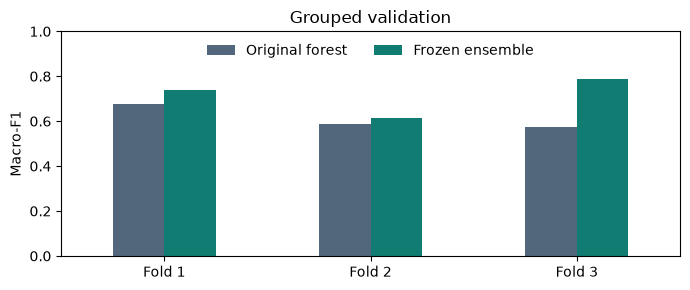

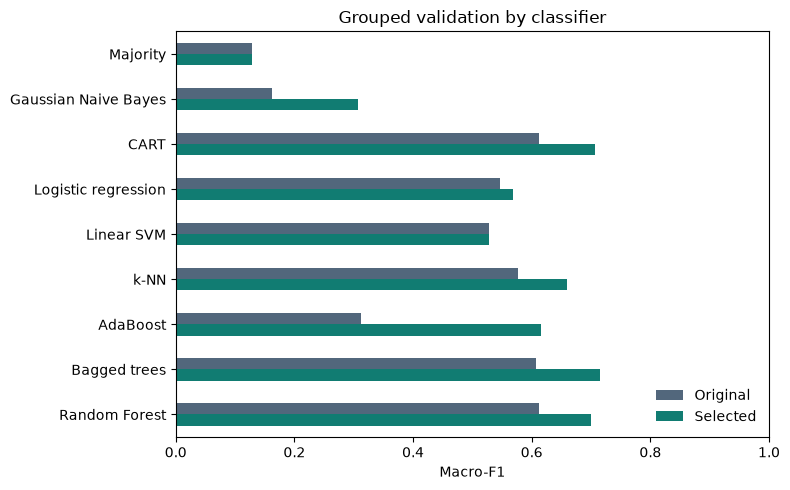

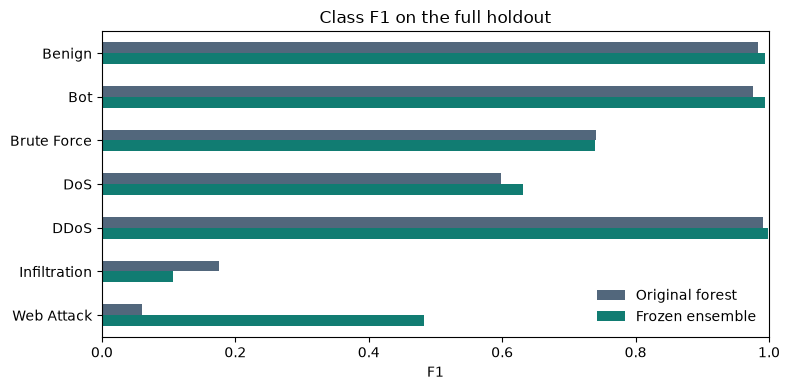

In [14]:
full_holdout = evaluate_full_holdout(fitted_classifiers)
overall_holdout, class_metrics = summarize_full_holdout()
display(overall_holdout.style.format({
    "Macro-F1": "{:.4f}", "Accuracy": "{:.2%}",
    "Benign false-alert count": "{:,.0f}", "Benign false-alert rate": "{:.2%}",
}))
display(class_metrics.round(4))
plot_comparisons(overall_cv, family_summary, class_metrics)

## Compare with the published results

The reference values come from the new bundle's result files. The table shows the reported and recomputed values side by side. The confusion counts are also compared exactly.

The saved run rebuilt the same split and class counts. On macOS, the refit scored 0.7063 full-holdout macro-F1 for the ensemble, compared with 0.7137 in the bundle. The bundle specifies scikit-learn 1.7.2 and minimum versions for the other libraries. The setup output records the versions used for this run.

In [15]:
REFERENCE = {'overall_cv': {'Original forest': {'cv_folds': [0.6778739456861272, 0.5855497207276855, 0.5755667946530117],
                                    'cv_macro_f1': 0.6129968203556082},
                'Frozen ensemble': {'cv_folds': [0.7414631282099321, 0.6221637430645066, 0.7996716360025671],
                                    'cv_macro_f1': 0.7210995024256687}},
 'overall_holdout': {'Original forest': {'macro_f1': 0.6476444316926673,
                                         'accuracy': 0.95748370718047,
                                         'benign_alert_rate': 0.023710152534984923,
                                         'benign_alerts': 71910,
                                         'f1': [0.9843219848081675,
                                                0.9760515533426689,
                                                0.7408720810499931,
                                                0.5993756974394547,
                                                0.9933321998565906,
                                                0.17746999618533407,
                                                0.062087509166462974],
                                         'confusion': [[2960968, 3390, 58, 1292, 1591, 61996, 3583],
                                                       [113, 75277, 0, 0, 0, 3, 163],
                                                       [0, 0, 73749, 6984, 0, 0, 0],
                                                       [237, 0, 44545, 39747, 0, 8, 25],
                                                       [138, 0, 0, 0, 134375, 6, 23],
                                                       [21923, 25, 2, 43, 46, 9072, 40],
                                                       [2, 0, 0, 0, 0, 1, 127]]},
                     'Frozen ensemble': {'macro_f1': 0.7137151797974124,
                                         'accuracy': 0.9749697053569767,
                                         'benign_alert_rate': 0.0018091726736123247,
                                         'benign_alerts': 5487,
                                         'f1': [0.9941150538737814,
                                                0.9934340031442802,
                                                0.7390988372093025,
                                                0.6302458730527783,
                                                0.9984685153520184,
                                                0.10241767625553719,
                                                0.5382262996941897],
                                         'confusion': [[3027391, 626, 32, 155, 165, 4404, 105],
                                                       [348, 75196, 0, 0, 9, 0, 3],
                                                       [0, 0, 71190, 9543, 0, 0, 0],
                                                       [506, 0, 40685, 43371, 0, 0, 0],
                                                       [238, 0, 0, 0, 134304, 0, 0],
                                                       [29225, 5, 0, 1, 0, 1919, 1],
                                                       [39, 3, 0, 0, 0, 0, 88]]}},
 'family_cv': {'Majority': {'Original': {'cv_macro_f1': 0.12884259444941035}},
               'Gaussian Naive Bayes': {'Original': {'cv_macro_f1': 0.16283246145996463},
                                        'Selected': {'cv_macro_f1': 0.3076643963188482}},
               'CART': {'Original': {'cv_macro_f1': 0.6059010345746497},
                        'Selected': {'cv_macro_f1': 0.709720760558926}},
               'Logistic regression': {'Original': {'cv_macro_f1': 0.5446607481686648},
                                       'Selected': {'cv_macro_f1': 0.5673642174361215}},
               'Linear SVM': {'Original': {'cv_macro_f1': 0.5275046950643664}},
               'k-NN': {'Original': {'cv_macro_f1': 0.5770658172030796},
                        'Selected': {'cv_macro_f1': 0.6590459844945697}},
               'AdaBoost': {'Original': {'cv_macro_f1': 0.3116310318270063},
                            'Selected': {'cv_macro_f1': 0.615571415666981}},
               'Bagged trees': {'Original': {'cv_macro_f1': 0.6071247092276025},
                                'Selected': {'cv_macro_f1': 0.7140703260774393}},
               'Random Forest': {'Original': {'cv_macro_f1': 0.6129968203556082},
                                 'Selected': {'cv_macro_f1': 0.7132277466615142}}},
 'family_holdout': {'Majority': {'Original': {'macro_f1': 0.13388118085921297, 'fit_rows': 25798}},
                    'Gaussian Naive Bayes': {'Original': {'macro_f1': 0.15481196578991785, 'fit_rows': 25798},
                                             'Selected': {'macro_f1': 0.27332550526162186, 'fit_rows': 75798}},
                    'CART': {'Original': {'macro_f1': 0.6324646201798053, 'fit_rows': 25798},
                             'Selected': {'macro_f1': 0.6694395255435946, 'fit_rows': 75798}},
                    'Logistic regression': {'Original': {'macro_f1': 0.47601687865175707, 'fit_rows': 25798},
                                            'Selected': {'macro_f1': 0.49858097215669084, 'fit_rows': 25798}},
                    'Linear SVM': {'Original': {'macro_f1': 0.44295586016301464, 'fit_rows': 25798}},
                    'k-NN': {'Original': {'macro_f1': 0.5541558054693664, 'fit_rows': 25798},
                             'Selected': {'macro_f1': 0.6006189536242703, 'fit_rows': 109458}},
                    'AdaBoost': {'Original': {'macro_f1': 0.25826526611500034, 'fit_rows': 25798},
                                 'Selected': {'macro_f1': 0.6499258091285333, 'fit_rows': 75798}},
                    'Bagged trees': {'Original': {'macro_f1': 0.6417136736030924, 'fit_rows': 25798},
                                     'Selected': {'macro_f1': 0.6985233559589716, 'fit_rows': 109458}},
                    'Random Forest': {'Original': {'macro_f1': 0.6466752645302735, 'fit_rows': 25798},
                                      'Selected': {'macro_f1': 0.7175104913469761, 'fit_rows': 109458}}},
 'regression': {'Original': {'mean_mae': 1.5306871334711711, 'mean_r2': 0.6806741158167521},
                'Selected': {'mean_mae': 0.6091829830195535, 'mean_r2': 0.8359615910325684}},
 'clustering': {'K-means': {'Original': {'mean_silhouette': 0.5393511056900024,
                                         'mean_adjusted_rand': 0.020614059963906278},
                            'Selected': {'mean_silhouette': 0.5393511056900024,
                                         'mean_adjusted_rand': 0.020614059963906278}},
                'Hierarchical': {'Original': {'mean_silhouette': 0.42894016702969867,
                                              'mean_adjusted_rand': 0.0021731086505425903},
                                 'Selected': {'mean_silhouette': 0.5778608918190002,
                                              'mean_adjusted_rand': -0.009670788476946095}}}}

In [16]:
def compare_to_bundle():
    rows = []

    def add(result, actual, reported, decimals=4):
        rows.append({
            "Result": result,
            "Recomputed": actual,
            "Reported": reported,
            "Difference": actual - reported,
            "Matches at reported precision": round(float(actual), decimals) == round(float(reported), decimals),
        })

    for label, reference in REFERENCE["overall_cv"].items():
        for f, expected in enumerate(reference["cv_folds"], 1):
            add(f"{label} · CV {f} macro-F1", validation["Overall", label][f-1]["macro_f1"], expected)
        add(f"{label} · mean CV macro-F1", mean_cv("Overall", label), reference["cv_macro_f1"])

    for label, reference in REFERENCE["overall_holdout"].items():
        for key in ("macro_f1", "accuracy", "benign_alert_rate", "benign_alerts"):
            add(f"{label} · full holdout {key.replace('_', ' ')}", full_holdout[label][key], reference[key])
        for idx, name in enumerate(LABELS):
            add(f"{label} · {name} F1", full_holdout[label]["f1"][idx], reference["f1"][idx])

    for name, configs in REFERENCE["family_cv"].items():
        for label, reference in configs.items():
            add(f"{name} · {label} CV macro-F1", mean_cv(name, label), reference["cv_macro_f1"])
            add(f"{name} · {label} sample macro-F1", family_holdout[name, label]["macro_f1"],
                REFERENCE["family_holdout"][name][label]["macro_f1"])

    for label, reference in REFERENCE["regression"].items():
        current = regression_summary.loc[label]
        add(f"Regression · {label} MAE", current["MAE"], reference["mean_mae"])
        add(f"Regression · {label} R²", current["R²"], reference["mean_r2"])

    for method, configs in REFERENCE["clustering"].items():
        for label, reference in configs.items():
            current = cluster_summary.loc[method, label]
            add(f"{method} · {label} silhouette", current["Silhouette"], reference["mean_silhouette"])
            add(f"{method} · {label} adjusted Rand", current["Adjusted Rand"], reference["mean_adjusted_rand"])

    return pd.DataFrame(rows).set_index("Result")


bundle_comparison = compare_to_bundle()
exact_confusions = pd.Series(
    {label: np.array_equal(row["confusion"], REFERENCE["overall_holdout"][label]["confusion"])
     for label, row in full_holdout.items()}, name="Exact confusion count match",
)
match_count = int(bundle_comparison["Matches at reported precision"].sum())
print(f"{match_count} of {len(bundle_comparison)} reported values match at the displayed precision.")
display(exact_confusions)
with pd.option_context("display.max_rows", None):
    display(bundle_comparison.round(6))

29 of 74 reported values match at the displayed precision.


Original forest    False
Frozen ensemble    False
Name: Exact confusion count match, dtype: bool

,Recomputed,Reported,Difference,Matches at reported precision
Result,,,,
Original forest · CV 1 macro-F1,0.678561,0.677874,0.000688,False
Original forest · CV 2 macro-F1,0.587428,0.585550,0.001879,False
Original forest · CV 3 macro-F1,0.573213,0.575567,-0.002353,False
Original forest · mean CV macro-F1,0.613068,0.612997,0.000071,False
Frozen ensemble · CV 1 macro-F1,0.738407,0.741463,-0.003056,False
Frozen ensemble · CV 2 macro-F1,0.612391,0.622164,-0.009772,False
Frozen ensemble · CV 3 macro-F1,0.789245,0.799672,-0.010427,False
Frozen ensemble · mean CV macro-F1,0.713348,0.721100,-0.007752,False
Original forest · full holdout macro f1,0.646566,0.647644,-0.001078,False
